# AquaPriorité — accès à l’eau et allocation sous budget

**Simulation pédagogique : données synthétiques.**

Le jeu couvre 180 territoires, des zones rurales et urbaines et vingt années. Les taux d’accès ne sont pas tous observés ; budgets et coûts unitaires sont simulés. Les pays fictifs ne possèdent pas de coordonnées géographiques réelles, une carte serait donc trompeuse.

## Objectif et démarche

Construire une liste argumentée de territoires, distinguer ampleur du besoin, rendement théorique du budget et robustesse du classement.

- Quelle part de la population dispose d’une donnée observée ? Les taux agrégés changent-ils lorsqu’on pondère correctement ?
- Quels écarts ruraux/urbains observe-t-on et comment évoluent les besoins dans chaque région ?
- Quel nombre de bénéficiaires pourrait théoriquement être couvert par le budget sans dépasser le besoin observé ?
- Quels territoires peuvent être classés lorsque les deux zones doivent être documentées ? Que devient la priorité sous trois pondérations ?
- Quels indicateurs de confiance et de couverture doivent accompagner le tableau de bord pour éviter une fausse précision ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
nc, ny = (180, 20)

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
pays = pd.DataFrame({'pays_id': np.arange(nc), 'region': np.repeat(['Region A', 'Region B', 'Region C', 'Region D', 'Region E', 'Region F'], 30), 'pays': ['Territoire fictif ' + str(i) for i in range(nc)]})

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
d = pd.MultiIndex.from_product([np.arange(nc), np.arange(2005, 2025), ['Rural', 'Urbain']], names=['pays_id', 'annee', 'zone']).to_frame(index=False)
base = RNG.uniform(25, 90, nc)
d['population'] = np.round(RNG.uniform(500000.0, 60000000.0, nc)[d.pays_id] * np.where(d.zone.eq('Rural'), 0.58, 0.42) * 1.018 ** (d.annee - 2005)).astype(int)

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
d['acces_sur_pct'] = np.clip(base[d.pays_id] + (d.annee - 2005) * RNG.uniform(0.2, 1.2, nc)[d.pays_id] + np.where(d.zone.eq('Urbain'), 12, 0) + RNG.normal(0, 2, len(d)), 0, 100)
d['budget_millions_eur'] = RNG.uniform(5, 100, len(d))
d['cout_beneficiaire_eur'] = RNG.uniform(80, 400, len(d))
d.loc[RNG.choice(len(d), 120, False), 'acces_sur_pct'] = np.nan
d.loc[:19, 'population'] = -1
d = pd.concat([d, d.iloc[300:340]], ignore_index=True)

## Étape 8 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [10]:
source(pays, 'pays', 'pays')
source(d, 'eau', 'pays-année-zone', {'acces_sur_pct': '% population, service sûr simulé', 'population': 'personnes', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne'})

## Étape 9 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [11]:
v = clean(d, ['pays_id', 'annee', 'zone'], lambda x: x.population.gt(0) & (x.acces_sur_pct.isna() | x.acces_sur_pct.between(0, 100)), 'eau')
v = v.merge(pays, on='pays_id', validate='many_to_one')
v['population_observee'] = v.population.where(v.acces_sur_pct.notna(), 0)
v['personnes_sans_acces'] = v.population * (1 - v.acces_sur_pct / 100)

## Étape 10 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [12]:
regions = v.groupby(['region', 'annee']).agg(sans_acces=('personnes_sans_acces', lambda x: x.sum(min_count=1)), population_observee=('population_observee', 'sum'), population_totale=('population', 'sum')).reset_index()
regions['sans_acces_pct'] = 100 * regions.sans_acces / regions.population_observee
regions['couverture_observation'] = regions.population_observee / regions.population_totale

## Étape 11 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [13]:
latest = v[v.annee == 2024].copy()
latest['beneficiaires_potentiels'] = np.minimum(latest.personnes_sans_acces, latest.budget_millions_eur * 1000000.0 / latest.cout_beneficiaire_eur)

## Étape 12 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [14]:
country = latest.groupby('pays_id').agg(sans_acces=('personnes_sans_acces', lambda x: x.sum(min_count=2)), beneficiaires=('beneficiaires_potentiels', lambda x: x.sum(min_count=2)), cout=('cout_beneficiaire_eur', 'mean'), zones_observees=('acces_sur_pct', 'count')).reset_index().merge(pays, on='pays_id', validate='one_to_one')
country['eligible'] = country.zones_observees.eq(2)
elig = country[country.eligible].copy()

## Étape 13 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [15]:
for col in ['sans_acces', 'beneficiaires', 'cout']:
    elig[col + '_score'] = elig[col].rank(pct=True, ascending=col != 'cout')

## Étape 14 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [16]:
ranking = []

## Étape 15 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [17]:
for wn, wb, wc in [(0.5, 0.3, 0.2), (0.3, 0.5, 0.2), (0.4, 0.2, 0.4)]:
    score = wn * elig.sans_acces_score + wb * elig.beneficiaires_score + wc * elig.cout_score
    ranking.append(pd.DataFrame({'pays_id': elig.pays_id, 'scenario': str((wn, wb, wc)), 'score': score, 'rang': score.rank(ascending=False, method='min')}))

## Étape 16 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [18]:
ranks = pd.concat(ranking)
stable = ranks.groupby('pays_id').agg(rang_min=('rang', 'min'), rang_max=('rang', 'max'), rang_moyen=('rang', 'mean')).reset_index()
stable['amplitude'] = stable.rang_max - stable.rang_min

## Étape 17 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [19]:
csv(v, CLEAN / 'eau_tableau.csv')
csv(country, CLEAN / 'priorites_tableau.csv')
figure('besoin_regional', lambda ax: regions.pivot(index='annee', columns='region', values='sans_acces_pct').plot(ax=ax, ylabel='% sans accès, population observée'))
figure('stabilite_priorites', lambda ax: stable.nsmallest(20, 'rang_moyen').plot(x='pays_id', y=['rang_min', 'rang_max'], kind='bar', ax=ax))

## Étape 18 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

                           indicateur        valeur
0                        observations  7.180000e+03
1            valeurs_acces_manquantes  1.200000e+02
2                 pays_eligibles_2024  1.700000e+02
3                    pays_exclus_2024  1.000000e+01
4  beneficiaires_potentiels_eligibles  7.276735e+07

- 170 pays fictifs avec deux zones observées en 2024 peuvent être classés.

- 120 valeurs manquantes conservées ; taux régionaux accompagnés de couverture.

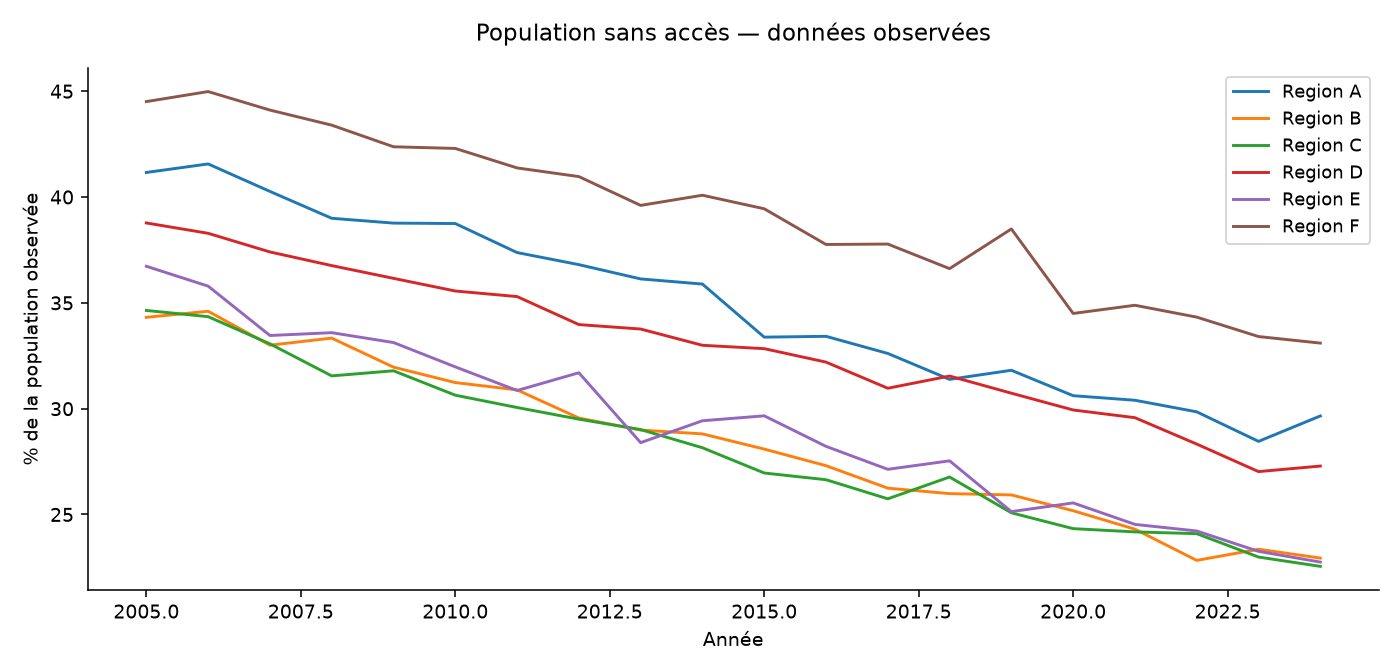

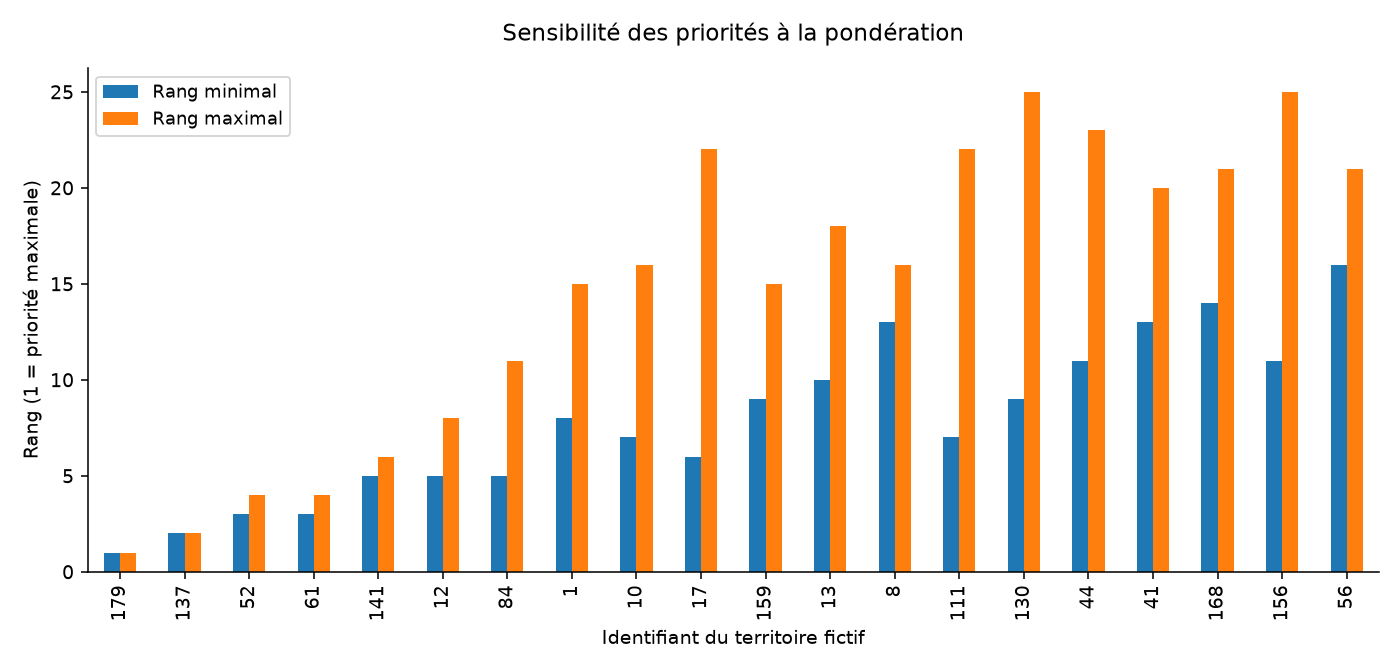

In [20]:
finish('AquaPriorité — priorisation des investissements', 'Quels territoires explorer sous contraintes budgétaires et données incomplètes ?', {'observations': len(v), 'valeurs_acces_manquantes': int(v.acces_sur_pct.isna().sum()), 'pays_eligibles_2024': len(elig), 'pays_exclus_2024': int((~country.eligible).sum()), 'beneficiaires_potentiels_eligibles': elig.beneficiaires.sum()}, {'regions_annees': regions, 'priorites': country, 'sensibilite_rangs': ranks, 'stabilite': stable}, [f'{len(elig)} pays fictifs avec deux zones observées en 2024 peuvent être classés.', f'{int(v.acces_sur_pct.isna().sum())} valeurs manquantes conservées ; taux régionaux accompagnés de couverture.'], ['Comparer trois pondérations et privilégier les priorités stables.', 'Afficher couverture, unité et année dans les infobulles.'], ['Aucune donnée réelle OMS/JMP ou géographique ; aucune carte de pays fictifs.', 'Bénéficiaires théoriques sans faisabilité locale.', 'Taux pondérés sur population observée ; ne pas assimiler les manquants à un accès nul.', 'Classeur Tableau natif non fourni : données, calculs et guide de construction livrés.'])

In [21]:
import pandas as pd, numpy as np
from scipy.optimize import milp, Bounds, LinearConstraint

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [22]:
r = Restitution()

In [23]:
m = r.m

In [24]:
n = r.number

In [25]:
p = r.pct

In [26]:
e = r.money

In [27]:
v = r.read('data/processed/eau_tableau.csv')

In [28]:
regions = r.read('analysis/regions_annees.csv')

In [29]:
country = r.read('analysis/priorites.csv')

In [30]:
ranks = r.read('analysis/sensibilite_rangs.csv')

In [31]:
stable = r.read('analysis/stabilite.csv')

In [32]:
latest = v[v.annee.eq(2024)].copy()

In [33]:
latest['beneficiaires'] = np.minimum(latest.personnes_sans_acces, latest.budget_millions_eur * 1000000.0 / latest.cout_beneficiaire_eur)

In [34]:
latest['cout_projet_eur'] = latest.beneficiaires * latest.cout_beneficiaire_eur

In [35]:
costs = latest.groupby('pays_id').cout_projet_eur.sum(min_count=2).rename('cout_projet_eur').reset_index()

In [36]:
elig = country[country.eligible].merge(costs, on='pays_id', validate='one_to_one').sort_values('pays_id').reset_index(drop=True)

In [37]:
elig['rendement_personnes_million'] = elig.beneficiaires / (elig.cout_projet_eur / 1000000.0)

In [38]:
budget = 500.0

In [39]:
max_projects = 12

In [40]:
regs = sorted(elig.region.unique())

In [41]:
A = np.vstack([elig.cout_projet_eur / 1000000.0, np.ones(len(elig))] + [elig.region.eq(g).astype(float).to_numpy() for g in regs])

In [42]:
lower = [0, 0] + [1] * len(regs)

In [43]:
upper = [budget, max_projects] + [np.inf] * len(regs)

In [44]:
opt = milp(c=-elig.beneficiaires.to_numpy() / 1000000.0, integrality=np.ones(len(elig)), bounds=Bounds(0, 1), constraints=LinearConstraint(A, lower, upper), options={'time_limit': 30, 'mip_rel_gap': 0})

In [45]:
if not opt.success:
    raise RuntimeError('Allocation non résolue : ' + opt.message)

In [46]:
selected = opt.x > 0.5

In [47]:
spent = elig.loc[selected, 'cout_projet_eur'].sum()

In [48]:
benefit = elig.loc[selected, 'beneficiaires'].sum()

In [49]:
assert spent <= budget * 1000000.0 + 0.01 and selected.sum() <= max_projects

In [50]:
for g in regs:
    assert (selected & elig.region.eq(g)).any()

In [51]:
chosen = []

In [52]:
for g in regs:
    chosen.append(int(elig[elig.region.eq(g)].cout_projet_eur.idxmin()))

In [53]:
used = elig.loc[chosen, 'cout_projet_eur'].sum()

In [54]:
for idx in elig.sort_values('rendement_personnes_million', ascending=False).index:
    if idx not in chosen and len(chosen) < max_projects and (used + elig.loc[idx, 'cout_projet_eur'] <= budget * 1000000.0):
        chosen.append(int(idx))
        used += elig.loc[idx, 'cout_projet_eur']

In [55]:
greedy = elig.loc[chosen, 'beneficiaires'].sum()

In [56]:
allocation = elig.assign(selection_optimale=selected, selection_heuristique=elig.index.isin(chosen))

In [57]:
regsel = allocation[allocation.selection_optimale].groupby('region').agg(projets=('pays_id', 'size'), beneficiaires=('beneficiaires', 'sum'), budget_eur=('cout_projet_eur', 'sum')).reset_index()

In [58]:
r.m.update({'budget_global_eur': budget * 1000000.0, 'cout_allocation_eur': spent, 'beneficiaires_allocation': benefit, 'projets_allocation': int(selected.sum()), 'beneficiaires_heuristique': greedy, 'ecart_optimisation_personnes': benefit - greedy})

In [59]:
recent = regions[regions.annee.eq(2024)].copy()

In [60]:
topsets = [set(d.nsmallest(20, 'rang').pays_id) for _, d in ranks.groupby('scenario')]

In [61]:
intersection = set.intersection(*topsets)

In [62]:
overlap = len(intersection)

In [63]:
st = stable.merge(country[['pays_id', 'region', 'eligible']], on='pays_id', validate='one_to_one').nsmallest(12, 'rang_moyen')

In [64]:
zone = latest.groupby('zone').agg(sans_acces=('personnes_sans_acces', lambda s: s.sum(min_count=1)), population_observee=('population_observee', 'sum'), population_totale=('population', 'sum')).reset_index()

In [65]:
zone['part_sans_acces'] = zone.sans_acces / zone.population_observee

In [66]:
zone['couverture'] = zone.population_observee / zone.population_totale

In [67]:
r.resume = [f"AquaPriorité analyse {n(m['observations'], 0)} observations territoire-année-zone ; {m['valeurs_acces_manquantes']} taux restent manquants et ne sont pas remplacés par zéro.", f"La photographie 2024 permet de classer {m['pays_eligibles_2024']} territoires ; {m['pays_exclus_2024']} n’ont pas les deux zones observées. {overlap} territoires sont communs aux trois top 20 de pondérations.", f'Sous 500 millions EUR, au plus douze projets et au moins un par région, l’optimisation choisit {int(selected.sum())} projets pour {n(benefit, 0)} bénéficiaires théoriques, avec {e(spent)} de dépense.', f'Le gain face à l’heuristique soumise aux mêmes contraintes est {n(benefit - greedy, 0)} bénéficiaires théoriques. Ce résultat dépend entièrement des coûts et besoins simulés, pas d’une faisabilité réelle.']

In [68]:
r.section('4. Ne pas confondre absence de donnée et absence d’accès', [f"Le jeu conserve {m['valeurs_acces_manquantes']} taux d’accès manquants. Pour ces lignes, la population observée vaut zéro au dénominateur de la statistique d’accès, mais le taux lui-même reste manquant. La population totale reste disponible afin de publier la couverture.", 'Le nombre sans accès est population × (1 − taux / 100). Le taux régional se calcule par somme des personnes sans accès / somme de population observée. Une moyenne simple de pourcentages ruraux, urbains ou territoriaux n’aurait pas les mêmes poids.', 'Les comparaisons temporelles doivent donc lire conjointement taux et couverture. Une amélioration apparente peut venir de l’arrivée de nouvelles données plutôt que d’un changement de service. La population non observée ne doit pas être qualifiée d’accédante ou de non-accédante.', 'Les définitions rurales et urbaines sont communes dans la simulation, mais pourraient varier dans une source réelle. Une comparaison internationale ou temporelle demanderait une revue des définitions et des années de collecte.'], [('Situation régionale en 2024', recent[['region', 'sans_acces_pct', 'couverture_observation', 'population_totale']]), ('Rural et urbain en 2024', zone)])

## 4. Ne pas confondre absence de donnée et absence d’accès

Le jeu conserve 120 taux d’accès manquants. Pour ces lignes, la population observée vaut zéro au dénominateur de la statistique d’accès, mais le taux lui-même reste manquant. La population totale reste disponible afin de publier la couverture.

Le nombre sans accès est population × (1 − taux / 100). Le taux régional se calcule par somme des personnes sans accès / somme de population observée. Une moyenne simple de pourcentages ruraux, urbains ou territoriaux n’aurait pas les mêmes poids.

Les comparaisons temporelles doivent donc lire conjointement taux et couverture. Une amélioration apparente peut venir de l’arrivée de nouvelles données plutôt que d’un changement de service. La population non observée ne doit pas être qualifiée d’accédante ou de non-accédante.

Les définitions rurales et urbaines sont communes dans la simulation, mais pourraient varier dans une source réelle. Une comparaison internationale ou temporelle demanderait une revue des définitions et des années de collecte.

### Situation régionale en 2024

       region  sans_acces_pct  couverture_observation  population_totale
19   Region A       29.655216                0.947371         1325966383
39   Region B       22.940318                0.923120         1376391623
59   Region C       22.549359                1.000000         1032507581
79   Region D       27.288426                0.991700         1218720017
99   Region E       22.751654                0.951657         1364107698
119  Region F       33.098211                1.000000         1353358395

### Rural et urbain en 2024

     zone    sans_acces  population_observee  population_totale  \
0   Rural  1.325466e+09           4269099378         4449209980   
1  Urbain  6.444549e+08           3150290808         3221841717   

   part_sans_acces  couverture  
0         0.310479    0.959519  
1         0.204570    0.977792  

In [69]:
r.section('5. Définir l’éligibilité et le potentiel de projet', [f"Un territoire entre dans le classement seulement si les deux zones possèdent un taux en 2024. {m['pays_eligibles_2024']} satisfont ce critère et {m['pays_exclus_2024']} sont écartés. L’exclusion évite une somme partielle, mais elle peut aussi écarter des territoires ayant besoin d’une meilleure collecte.", 'Le nombre théorique de bénéficiaires d’une zone est min(personnes sans accès, budget de zone / coût par bénéficiaire). Cette formule plafonne le bénéfice au besoin observé. Elle suppose un coût linéaire, aucune perte de financement, aucun coût fixe et un projet réalisable.', 'Le coût du projet territorial est la somme des bénéficiaires de chaque zone multipliés par leur coût propre. Utiliser simplement le coût moyen du territoire multiplierait un besoin et un coût mal pondérés. Le calcul est donc effectué au grain zone avant agrégation.', 'Un bénéficiaire théorique ne constitue pas une personne effectivement desservie. Les contraintes techniques, la disponibilité de l’eau, la maintenance, les droits locaux et la durée des travaux sont absents et doivent rester dans les réserves de décision.'])

## 5. Définir l’éligibilité et le potentiel de projet

Un territoire entre dans le classement seulement si les deux zones possèdent un taux en 2024. 170 satisfont ce critère et 10 sont écartés. L’exclusion évite une somme partielle, mais elle peut aussi écarter des territoires ayant besoin d’une meilleure collecte.

Le nombre théorique de bénéficiaires d’une zone est min(personnes sans accès, budget de zone / coût par bénéficiaire). Cette formule plafonne le bénéfice au besoin observé. Elle suppose un coût linéaire, aucune perte de financement, aucun coût fixe et un projet réalisable.

Le coût du projet territorial est la somme des bénéficiaires de chaque zone multipliés par leur coût propre. Utiliser simplement le coût moyen du territoire multiplierait un besoin et un coût mal pondérés. Le calcul est donc effectué au grain zone avant agrégation.

Un bénéficiaire théorique ne constitue pas une personne effectivement desservie. Les contraintes techniques, la disponibilité de l’eau, la maintenance, les droits locaux et la durée des travaux sont absents et doivent rester dans les réserves de décision.

In [70]:
r.section('6. Challenger un classement par les pondérations', ['Le scoring compare besoin, bénéficiaires potentiels et coût à partir de rangs normalisés. Trois scénarios changent les poids : 50/30/20, 30/50/20 et 40/20/40. La direction peut ainsi voir si une préférence sur le rendement ou le coût modifie fortement les priorités.', f'L’intersection des trois top 20 contient {overlap} territoires. Cette intersection identifie des candidats relativement robustes à ces trois préférences seulement ; elle ne garantit pas une robustesse aux données, aux coûts ou à un autre système de critères.', f'L’amplitude des rangs varie de {n(stable.amplitude.min(), 0)} à {n(stable.amplitude.max(), 0)}. Les territoires à forte amplitude doivent être présentés comme sensibles au choix du décideur, plutôt que comme ayant un rang unique objectivement vrai.', 'Un score n’est pas une allocation : il ne vérifie pas qu’un ensemble de projets rentre dans un budget global. C’est pourquoi une étape d’optimisation séparée est ajoutée. Elle répond à une autre question et n’a pas à reproduire le top du classement.'], [('Priorités et variation de rang', st)])

## 6. Challenger un classement par les pondérations

Le scoring compare besoin, bénéficiaires potentiels et coût à partir de rangs normalisés. Trois scénarios changent les poids : 50/30/20, 30/50/20 et 40/20/40. La direction peut ainsi voir si une préférence sur le rendement ou le coût modifie fortement les priorités.

L’intersection des trois top 20 contient 13 territoires. Cette intersection identifie des candidats relativement robustes à ces trois préférences seulement ; elle ne garantit pas une robustesse aux données, aux coûts ou à un autre système de critères.

L’amplitude des rangs varie de 0 à 50. Les territoires à forte amplitude doivent être présentés comme sensibles au choix du décideur, plutôt que comme ayant un rang unique objectivement vrai.

Un score n’est pas une allocation : il ne vérifie pas qu’un ensemble de projets rentre dans un budget global. C’est pourquoi une étape d’optimisation séparée est ajoutée. Elle répond à une autre question et n’a pas à reproduire le top du classement.

### Priorités et variation de rang

     pays_id  rang_min  rang_max  rang_moyen  amplitude    region  eligible
169      179       1.0       1.0    1.000000        0.0  Region F      True
128      137       2.0       2.0    2.000000        0.0  Region E      True
46        52       3.0       4.0    3.333333        1.0  Region B      True
54        61       3.0       4.0    3.666667        1.0  Region C      True
132      141       5.0       6.0    5.333333        1.0  Region E      True
11        12       5.0       8.0    6.666667        3.0  Region A      True
77        84       5.0      11.0    8.666667        6.0  Region C      True
1          1       8.0      15.0   10.666667        7.0  Region A      True
9         10       7.0      16.0   11.000000        9.0  Region A      True
16        17       6.0      22.0   12.000000       16.0  Region A      True
149      159       9.0      15.0   12.000000        6.0  Region F      True
12        13      10.0      18.0   13.333333        8.0  Region A      True

In [71]:
r.section('7. Allouer un budget global avec des contraintes explicites', ['Une variable binaire par territoire représente la sélection ou non du projet complet. L’objectif est de maximiser la somme des bénéficiaires théoriques. Les contraintes sont : coût total <= 500 millions EUR, au plus douze projets, au moins un projet dans chacune des six régions.', f'Le solveur trouve {int(selected.sum())} projets, {e(spent)} de coût et {n(benefit, 0)} bénéficiaires. Le budget restant est {e(budget * 1000000.0 - spent)}. Les contrôles vérifient budget, cardinalité et représentation régionale, au lieu de supposer que le rang a résolu le problème.', f'La règle de référence sélectionne d’abord le projet le moins cher de chaque région, puis ajoute les projets faisables par rendement décroissant. Elle produit {n(greedy, 0)} bénéficiaires. L’optimisation améliore ce total de {n(benefit - greedy, 0)} sous les mêmes contraintes ; le choix régional initial de l’heuristique est un compromis, pas un optimum.', 'Le résultat optimise le modèle écrit, pas le bien-être réel. Les coûts étant linéaires et les projets indivisibles, une petite différence d’hypothèse peut changer la sélection. Une analyse réelle devrait comparer plusieurs budgets, coûts, critères d’équité et risques d’exécution.'], [('Allocation optimale par région', regsel), ('Projets sélectionnés', allocation[allocation.selection_optimale][['pays_id', 'region', 'beneficiaires', 'cout_projet_eur', 'rendement_personnes_million']])])

## 7. Allouer un budget global avec des contraintes explicites

Une variable binaire par territoire représente la sélection ou non du projet complet. L’objectif est de maximiser la somme des bénéficiaires théoriques. Les contraintes sont : coût total <= 500 millions EUR, au plus douze projets, au moins un projet dans chacune des six régions.

Le solveur trouve 8 projets, 496 361 866 EUR de coût et 5 118 163 bénéficiaires. Le budget restant est 3 638 134 EUR. Les contrôles vérifient budget, cardinalité et représentation régionale, au lieu de supposer que le rang a résolu le problème.

La règle de référence sélectionne d’abord le projet le moins cher de chaque région, puis ajoute les projets faisables par rendement décroissant. Elle produit 4 903 551 bénéficiaires. L’optimisation améliore ce total de 214 612 sous les mêmes contraintes ; le choix régional initial de l’heuristique est un compromis, pas un optimum.

Le résultat optimise le modèle écrit, pas le bien-être réel. Les coûts étant linéaires et les projets indivisibles, une petite différence d’hypothèse peut changer la sélection. Une analyse réelle devrait comparer plusieurs budgets, coûts, critères d’équité et risques d’exécution.

### Allocation optimale par région

     region  projets  beneficiaires    budget_eur
0  Region A        1   0.000000e+00  0.000000e+00
1  Region B        1   0.000000e+00  0.000000e+00
2  Region C        1   1.030059e+06  8.697763e+07
3  Region D        2   1.768316e+06  1.783887e+08
4  Region E        2   1.927455e+06  1.800680e+08
5  Region F        1   3.923331e+05  5.092754e+07

### Projets sélectionnés

     pays_id    region  beneficiaires  cout_projet_eur  \
17        18  Region A   0.000000e+00     0.000000e+00   
35        40  Region B   0.000000e+00     0.000000e+00   
68        75  Region C   1.030059e+06     8.697763e+07   
102      110  Region D   7.186977e+05     7.347732e+07   
108      116  Region D   1.049619e+06     1.049114e+08   
128      137  Region E   1.030358e+06     9.201161e+07   
132      141  Region E   8.970962e+05     8.805640e+07   
152      162  Region F   3.923331e+05     5.092754e+07   

     rendement_personnes_million  
17                           NaN  
35                           NaN  
68                  11842.805038  
102                  9781.219037  
108                 10004.813673  
128                 11198.134756  
132                 10187.745522  
152                  7703.750722  

In [72]:
r.section('8. Rendre la décision vérifiable dans le tableau de bord', ['Les trois vues recommandées séparent couverture/tendance, priorités par scénario et allocation sous contraintes. Elles affichent année, unité, éligibilité, couverture et hypothèses de coût. Les territoires sont fictifs : une carte géographique serait trompeuse.', 'La table des scénarios contient plusieurs lignes par territoire. Une jointure physique non maîtrisée aux faits de population multiplierait les personnes et bénéficiaires. Les vues utilisent des sources séparées ou une relation contrôlée au grain adéquat.', 'La décision proposée est de retenir un panel robuste pour étude de faisabilité, puis de discuter les contraintes d’allocation. Le budget n’est pas un engagement et le gain théorique ne constitue pas une estimation d’impact sur le terrain.'])

## 8. Rendre la décision vérifiable dans le tableau de bord

Les trois vues recommandées séparent couverture/tendance, priorités par scénario et allocation sous contraintes. Elles affichent année, unité, éligibilité, couverture et hypothèses de coût. Les territoires sont fictifs : une carte géographique serait trompeuse.

La table des scénarios contient plusieurs lignes par territoire. Une jointure physique non maîtrisée aux faits de population multiplierait les personnes et bénéficiaires. Les vues utilisent des sources séparées ou une relation contrôlée au grain adéquat.

La décision proposée est de retenir un panel robuste pour étude de faisabilité, puis de discuter les contraintes d’allocation. Le budget n’est pas un engagement et le gain théorique ne constitue pas une estimation d’impact sur le terrain.

In [73]:
allocation.to_csv(r.root / 'analysis/allocation_budget.csv', sep=';', index=False, encoding='utf-8-sig')

In [74]:
r.actions = [('P1', str(m['valeurs_acces_manquantes']) + ' taux manquants', 'Publier couverture et périmètre observé', 'Aucune valeur manquante transformée en taux nul'), ('P1', str(overlap) + ' candidats communs aux top 20', 'Discuter préférences et faisabilité', 'Classement sensible présenté comme tel'), ('P1', e(spent) + ' sous 500 millions EUR', 'Vérifier les contraintes d’allocation', 'Budget, douze projets maximum et six régions contrôlés'), ('P2', n(benefit, 0) + ' bénéficiaires théoriques', 'Collecter coûts fixes et risques de réalisation', 'Potentiel comptable distinct d’un impact effectif')]

In [75]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

AquaPriorité analyse 7 180 observations territoire-année-zone ; 120 taux restent manquants et ne sont pas remplacés par zéro.

La photographie 2024 permet de classer 170 territoires ; 10 n’ont pas les deux zones observées. 13 territoires sont communs aux trois top 20 de pondérations.

Sous 500 millions EUR, au plus douze projets et au moins un par région, l’optimisation choisit 8 projets pour 5 118 163 bénéficiaires théoriques, avec 496 361 866 EUR de dépense.

Le gain face à l’heuristique soumise aux mêmes contraintes est 214 612 bénéficiaires théoriques. Ce résultat dépend entièrement des coûts et besoins simulés, pas d’une faisabilité réelle.

    0                                      1  \
0  P1                     120 taux manquants   
1  P1        13 candidats communs aux top 20   
2  P1  496 361 866 EUR sous 500 millions EUR   
3  P2     5 118 163 bénéficiaires théoriques   

                                                 2  \
0          Publier couverture et périmètre observé   
1              Discuter préférences et faisabilité   
2            Vérifier les contraintes d’allocation   
3  Collecter coûts fixes et risques de réalisation   

                                                   3  
0    Aucune valeur manquante transformée en taux nul  
1             Classement sensible présenté comme tel  
2  Budget, douze projets maximum et six régions c...  
3  Potentiel comptable distinct d’un impact effectif  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [76]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
